d:\GIT\Teaching Material\2025-26\3rd Sem\DIP Lab - AIML\Source Code\Expt 10\Images


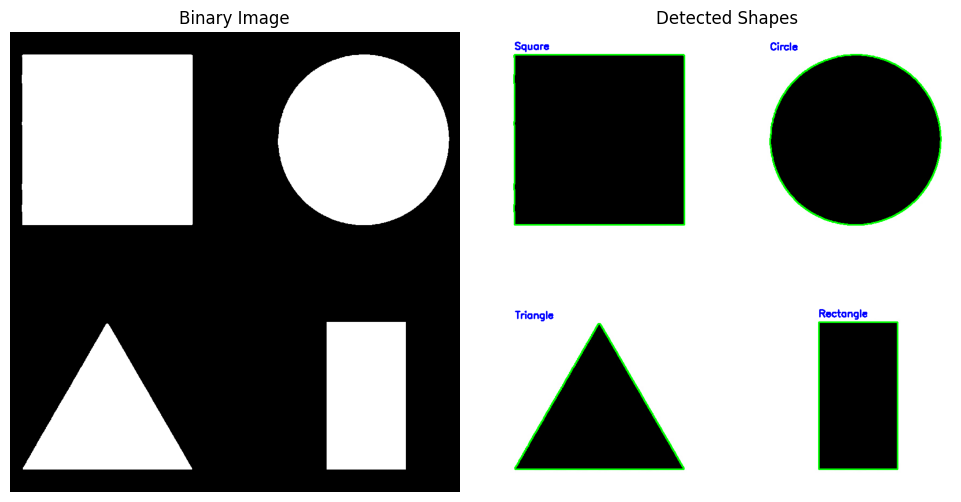

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import pathlib

# Set image path
image_path = pathlib.Path(os.path.join(os.getcwd(), "Images"))
print(image_path)

# Read input image
img = cv2.imread(image_path / "shapes.png")
if img is None:
    raise FileNotFoundError("Input image not found.")

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Apply thresholding
_, thresh = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY_INV)

# Find contours
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Copy image for drawing
output = img.copy()

# Loop through contours
for cnt in contours:

    area = cv2.contourArea(cnt)
    if area < 500:  # Ignore small noise
        continue

    # Perimeter
    perimeter = cv2.arcLength(cnt, True)

    # Polygon approximation
    epsilon = 0.04 * perimeter
    approx = cv2.approxPolyDP(cnt, epsilon, True)

    # Bounding rectangle
    x, y, w, h = cv2.boundingRect(approx)
    aspect_ratio = float(w) / h

    # Shape classification
    shape = "Unknown"

    if len(approx) == 3:
        shape = "Triangle"
    elif len(approx) == 4:
        if 0.95 <= aspect_ratio <= 1.05:
            shape = "Square"
        else:
            shape = "Rectangle"
    else:
        shape = "Circle"

    # Draw contour and label
    cv2.drawContours(output, [cnt], -1, (0, 255, 0), 2)
    cv2.putText(
        output, shape, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2
    )

# Display results
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title("Binary Image")
plt.imshow(thresh, cmap="gray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title("Detected Shapes")
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.axis("off")

plt.tight_layout()
plt.show()